# Example 1 (Section 5.1 of the paper): a system with a closed-form optimal controller

## Section 1. Koopman–Riccati controller synthesis

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

from dynamics import InputAffineSystem
from kernel import linear_matern_kernel, linear_gaussian_kernel
from koopman_synthesis import yosida_matrices, koopman_riccati, koopman_lyapunov, KoopmanController
from scipy.linalg import sqrtm
import time

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

### 1.1 The system and its optimal controller

$$
\begin{bmatrix}\dot x_1\\ \dot x_2\end{bmatrix} =
\begin{bmatrix}-x_1 + x_2\\ -\tfrac12 x_1 - \tfrac12 x_2\big(1-\gamma(x)^2\big)\end{bmatrix} +
\begin{bmatrix}0\\ \gamma(x)\end{bmatrix} u, \qquad \gamma(x) = 2 + \cos 2\pi x_1 .
$$

- **Optimal solution:** with stage cost $q(x) + u^2$ and $q(x) = |x|^2$, the HJB equation gives $v^\star(x) = \tfrac12 x_1^2 + x_2^2$ and $\pi^\star(x) = -x_2\,(2+\cos 2\pi x_1)$.
- **Open loop:** the origin is unstable, with eigenvalues $-0.90$ and $3.90$.
- **Linearized LQR:** the linearized system $\dot x_1 = -x_1 + x_2$, $\dot x_2 = -\tfrac12 x_1 + 4x_2 + 3u$ gives $\pi_{\rm LQR}(x) = -3x_2$.

In [2]:
gamma = lambda x: 2 + np.cos(2 * np.pi * x[0])
system = InputAffineSystem(lambda x: np.array([-x[0] + x[1], -0.5 * x[0] - 0.5 * x[1] * (1 - gamma(x) ** 2)]),
                           [lambda x: np.array([0.0, gamma(x)])], 2, 1, name="Example 1")
v_opt = lambda X: 0.5 * X[0] ** 2 + X[1] ** 2
pi_opt = lambda X: -X[1] * gamma(X)

A_lin, B_lin = system.linearize()
K_lqr = system.design_lqr(np.eye(2), np.eye(1))
print("open-loop eigenvalues:", np.linalg.eigvals(A_lin))
print("LQR gain of the linearization:", K_lqr, "-> pi_LQR(x) = -3 x2")

open-loop eigenvalues: [-0.8979  3.8979]
LQR gain of the linearization: [[0. 3.]] -> pi_LQR(x) = -3 x2


### 1.2 Data and Yosida-approximated matrices

- **Samples:** $n = 100$ points drawn uniformly in $\mathbb X = [-1, 1]^2$.
- **Data:** from each sample, the flows of $f_0$ and of $f_1$ (the latter *alone*) on $[0, \theta]$.
- **Kernel:** linear–Sobolev $\mathring\kappa(x, x') = (x\cdot x')\,\rho(|x-x'|)$, with $\rho$ the Matérn function of smoothness $s = 4.5$ (i.e. $\nu = 3.5$) and length scale 1.
- **Yosida parameters:** $\lambda = 200$ and $\theta = 0.125$, so that $e^{-\lambda\theta} = e^{-25}$ is negligible.
- **Regularization:** $\mathsf G$ is nearly singular, so $\mathsf G + \mu\mathsf I$ with $\mu = 10^{-5}$ replaces $\mathsf G$ wherever $\mathsf G$ is inverted.
- **Cost matrix:** $\mathsf Q_{ii'} = x_i\cdot x_{i'}$, which represents $q(x) = |x|^2$.

In [3]:
n, lam, theta, mu = 100, 200.0, 0.125, 1e-5
kernel = linear_matern_kernel(2, 4.5, 1.0)
data = system.collect_data(n, 1.0, tau=theta, n_time=401, rng=0, solver="RK45", rtol=1e-9, atol=1e-11)
X0 = data.X0
G, (A0, A1) = yosida_matrices(data, kernel, lam)
Qm = X0.T @ X0
Gmu = G + mu * np.eye(n)                     # regularized G, used wherever G is inverted
print(f"cond(G) = {np.linalg.cond(G):.1e}, cond(G + mu I) = {np.linalg.cond(Gmu):.1e}")

u_lqr = -K_lqr @ X0                          # initial policy: linearized LQR at the samples, shape (1, n)
A_hat, B_hat = np.linalg.solve(Gmu, A0), np.linalg.solve(Gmu, A1)
print("largest real parts of eig((G+mu I)^-1 A^0)            (open loop):",
      np.sort(np.linalg.eigvals(A_hat).real)[::-1][:3])
print("largest real parts of eig((G+mu I)^-1 (A^0 + A^1 Diag u)) (LQR):",
      np.sort(np.linalg.eigvals(A_hat + B_hat * u_lqr).real)[::-1][:3])

[Example 1] data collection: 100 samples x 2 vector fields: total computational time = 0.0463 s


/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:46: RuntimeWarning: divide by zero encountered in matmul
  sq = np.sum(X ** 2, 0)[:, None] + np.sum(Xp ** 2, 0)[None, :] - 2.0 * X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:46: RuntimeWarning: overflow encountered in matmul
  sq = np.sum(X ** 2, 0)[:, None] + np.sum(Xp ** 2, 0)[None, :] - 2.0 * X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:46: RuntimeWarning: invalid value encountered in matmul
  sq = np.sum(X ** 2, 0)[:, None] + np.sum(Xp ** 2, 0)[None, :] - 2.0 * X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:223: RuntimeWarning: divide by zero encountered in matmul
  return X.T @ Xp
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/ke

cond(G) = 8.3e+11, cond(G + mu I) = 3.6e+06
largest real parts of eig((G+mu I)^-1 A^0)            (open loop): [9.8562 9.7511 9.7511]
largest real parts of eig((G+mu I)^-1 (A^0 + A^1 Diag u)) (LQR): [-0.0001 -0.0001 -0.0001]


/var/folders/md/vvnkg65d02s5flkyy8d296340000gn/T/ipykernel_5926/2414631261.py:6: RuntimeWarning: divide by zero encountered in matmul
  Qm = X0.T @ X0
/var/folders/md/vvnkg65d02s5flkyy8d296340000gn/T/ipykernel_5926/2414631261.py:6: RuntimeWarning: overflow encountered in matmul
  Qm = X0.T @ X0
/var/folders/md/vvnkg65d02s5flkyy8d296340000gn/T/ipykernel_5926/2414631261.py:6: RuntimeWarning: invalid value encountered in matmul
  Qm = X0.T @ X0


The open-loop matrix has unstable eigenvalues, as expected for an unstable origin. Its leading eigenvalues (about 9.8) are larger than the Yosida image $\lambda\mu/(\lambda-\mu) = 4.06$ of the unstable eigenvalue $\mu = 3.90$; they may come from higher-order Koopman modes or from approximation errors. Under the linearized-LQR policy the closed-loop matrix is Hurwitz, though only barely (leading real part about $-10^{-4}$), so this policy is a valid starting point for the Kleinman iteration.

### 1.3 Kleinman iteration

With $\mathsf Y = \mathsf{GPG}$, $\mathsf A = \mathsf G^{-1}\mathsf A^0$, $\mathsf B_j = \mathsf G^{-1}\mathsf A^j$ (with $\mathsf G + \mu\mathsf I$ in place of $\mathsf G$) and $\mathsf A_u = \mathsf A + \sum_j \mathsf B_j \operatorname{Diag}\mathsf u_j$, each iteration consists of two steps:

- **policy evaluation**, a Lyapunov equation: $\mathsf Y\mathsf A_u + \mathsf A_u^\top \mathsf Y + \mathsf Q + \sum_j \mathsf u_j\mathsf u_j^\top = 0$;
- **policy improvement:** $\mathsf u_j = -\operatorname{diag}(\mathsf{GPA}^j) = -\operatorname{diag}(\mathsf Y\mathsf B_j)$.

**Stopping rule:** the iteration stops when $\|\mathsf u_{\rm new} - \mathsf u\|_\infty < 10^{-6}$, after 500 iterations, or when $\mathsf A_u$ is no longer Hurwitz. In the last case the last stabilizing policy and its $\mathsf P$ are returned.

/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/koopman_synthesis.py:76: RuntimeWarning: divide by zero encountered in matmul
  u = np.stack([-np.diag(Y @ B) for B in Bs])                     # policy improvement
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/koopman_synthesis.py:76: RuntimeWarning: overflow encountered in matmul
  u = np.stack([-np.diag(Y @ B) for B in Bs])                     # policy improvement
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/koopman_synthesis.py:76: RuntimeWarning: invalid value encountered in matmul
  u = np.stack([-np.diag(Y @ B) for B in Bs])                     # policy improvement


121 iterations (converged), computational time = 0.680 s; last change in u = 9.9e-07


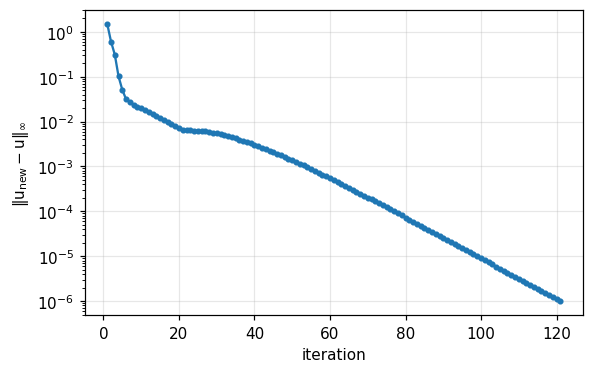

max Re eig(A_u) over the accepted iterations: -0.00
at the samples: rel. error of u = 0.094, rel. error of v = 0.063


In [4]:
P, u, info = koopman_riccati(G, [A0, A1], Qm, u_lqr, tol=1e-6, max_iter=500, mu=mu)
print(f"{info['iterations']} iterations ({info['stop']}), computational time = {info['wall_time']:.3f} s; "
      f"last change in u = {info['history'][-1, 0]:.1e}")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.semilogy(np.arange(1, info["iterations"] + 1), info["history"][:, 0], "o-", ms=3)
ax.set(xlabel="iteration", ylabel=r"$\|\mathsf{u}_{\mathrm{new}} - \mathsf{u}\|_\infty$")
plt.tight_layout(); plt.savefig("ex1fig1.png", dpi=300, bbox_inches="tight"); plt.show()
print(f"max Re eig(A_u) over the accepted iterations: {info['history'][:, 1].max():.2f}")

u_star, v_star = pi_opt(X0), v_opt(X0)
v_samples = np.einsum("in,ij,jn->n", G, P, G)
print(f"at the samples: rel. error of u = {np.linalg.norm(u[0] - u_star) / np.linalg.norm(u_star):.3f}, "
      f"rel. error of v = {np.linalg.norm(v_samples - v_star) / np.linalg.norm(v_star):.3f}")

### 1.4 Value function and policy compared with the true optimal solution and the LQR

- **Value function:** $v_{\rm Koopman\text{-}Riccati}(x) = \mathsf g(x)^\top \mathsf P\,\mathsf g(x)$ can be evaluated anywhere.
- **Policy:** it is known at the samples and interpolated elsewhere (Remark 3.18) by kernel ridge regression with a linear–Gaussian kernel ($\sigma = 0.5$, regularization $10^{-3}$; a smaller regularization reproduces the samples exactly but overshoots in regions without samples).
- **LQR column:**
  - $v_{\rm LQR}$ is the *realized* cost $\int_0^{20}(|x|^2 + u^2)\,dt$ of the linearized LQR $u = -3x_2$ applied to the nonlinear system from each grid point.
  - It is not $x^\top \mathsf P_{\rm LQR}\, x$: in this example that quadratic form coincides with $v_{\rm true}$, because $v_{\rm true}$ is itself quadratic.

/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:78: RuntimeWarning: divide by zero encountered in matmul
  return self.alpha @ self.kernel.matrix(self.X_train, _cols(X))
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:78: RuntimeWarning: overflow encountered in matmul
  return self.alpha @ self.kernel.matrix(self.X_train, _cols(X))
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/kernel.py:78: RuntimeWarning: invalid value encountered in matmul
  return self.alpha @ self.kernel.matrix(self.X_train, _cols(X))
/var/folders/md/vvnkg65d02s5flkyy8d296340000gn/T/ipykernel_5926/944075328.py:8: RuntimeWarning: divide by zero encountered in matmul
  Pil = (-K_lqr @ Xg)[0].reshape(g1.shape)
/var/folders/md/vvnkg65d02s5flkyy8d296340000gn/T/ipykernel_5926/944075328.py:8: RuntimeWarning: overflow encountered in matmul
  Pil = (-K_lqr @ Xg)[0

max |x(20)| under LQR over the grid: 2.3e-10
on the grid over [-1,1]^2: max |v_KR - v_true| = 0.348, realized LQR cost - v_true in [-0.000, 0.575]; max |pi_KR - pi_true| = 0.844, max |pi_LQR - pi_true| = 2.000


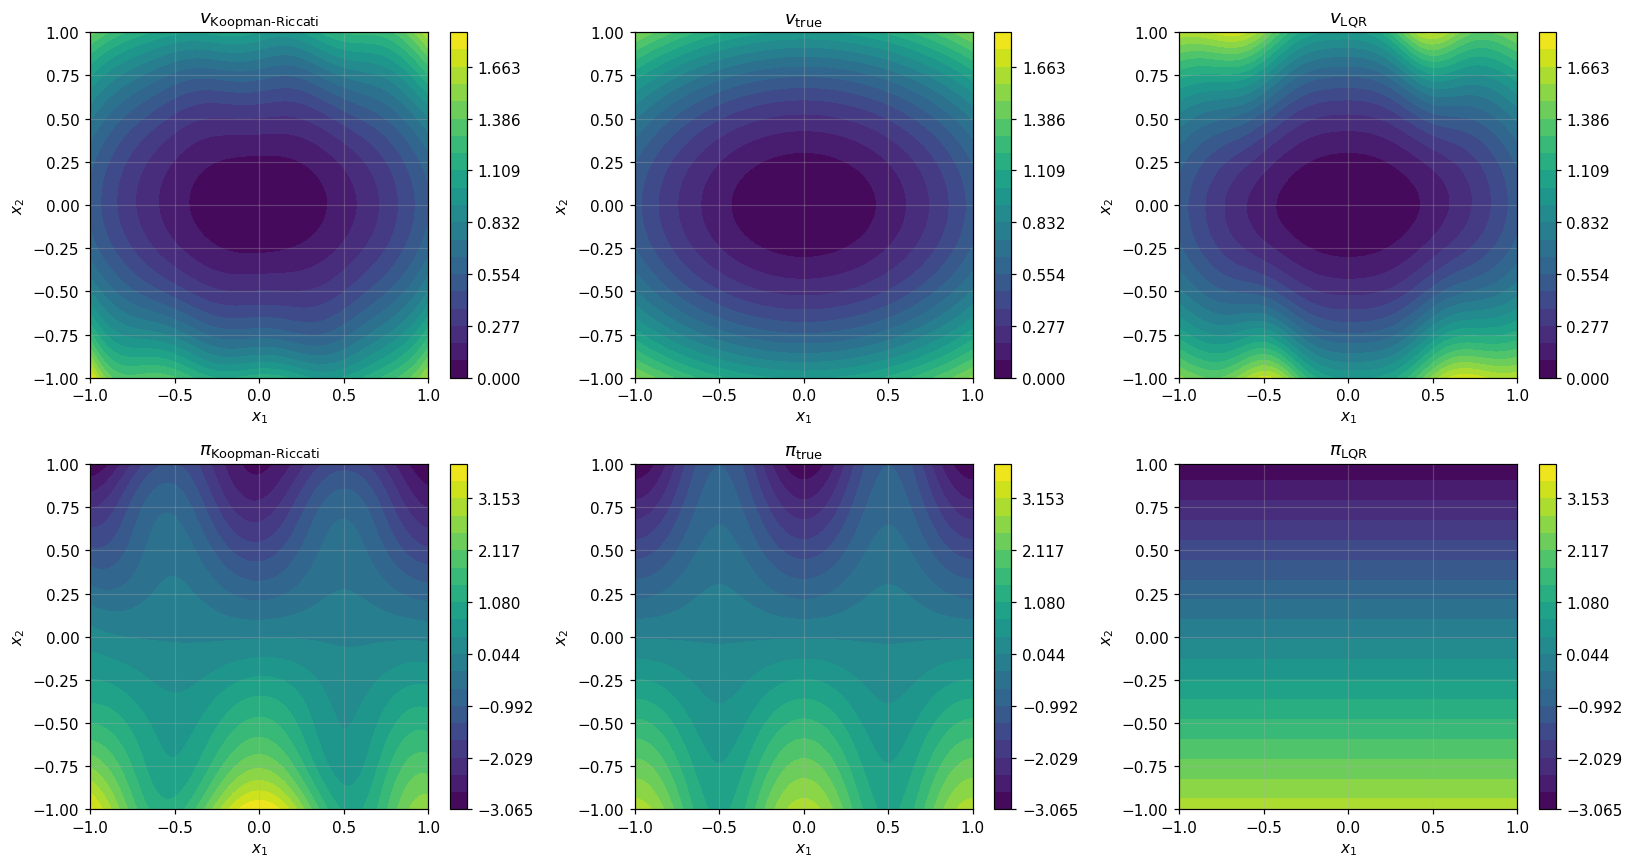

In [5]:
from scipy.integrate import solve_ivp

ctrl = KoopmanController(kernel, X0, P, u, linear_gaussian_kernel(0.5), reg=1e-3)
g1, g2 = np.meshgrid(np.linspace(-1, 1, 81), np.linspace(-1, 1, 81))
Xg = np.vstack([g1.ravel(), g2.ravel()])
V, Vs = ctrl.value(Xg).reshape(g1.shape), v_opt(Xg).reshape(g1.shape)
Pi, Pis = ctrl.policy_model.predict(Xg)[0].reshape(g1.shape), pi_opt(Xg).reshape(g1.shape)
Pil = (-K_lqr @ Xg)[0].reshape(g1.shape)

# Realized cost of the linearized LQR on the nonlinear system, from every grid point at once:
# state z = [x1 (M), x2 (M), c (M)] with dc/dt = |x|^2 + u^2, u = -K x, on [0, 20].
def lqr_closed_loop(t, z):
    x1, x2 = z.reshape(3, -1)[:2]
    u_ = -(K_lqr[0, 0] * x1 + K_lqr[0, 1] * x2)
    g = 2 + np.cos(2 * np.pi * x1)
    return np.concatenate([-x1 + x2, -0.5 * x1 - 0.5 * x2 * (1 - g ** 2) + g * u_, x1 ** 2 + x2 ** 2 + u_ ** 2])

sol = solve_ivp(lqr_closed_loop, (0, 20), np.concatenate([Xg[0], Xg[1], np.zeros(Xg.shape[1])]), rtol=1e-8, atol=1e-10)
Vl = sol.y[2 * Xg.shape[1]:, -1].reshape(g1.shape)
print(f"max |x(20)| under LQR over the grid: {np.max(np.hypot(*sol.y[:2 * Xg.shape[1], -1].reshape(2, -1))):.1e}")
print(f"on the grid over [-1,1]^2: max |v_KR - v_true| = {np.abs(V - Vs).max():.3f}, "
      f"realized LQR cost - v_true in [{(Vl - Vs).min():.3f}, {(Vl - Vs).max():.3f}]; "
      f"max |pi_KR - pi_true| = {np.abs(Pi - Pis).max():.3f}, max |pi_LQR - pi_true| = {np.abs(Pil - Pis).max():.3f}")

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for row, (Fs, name) in enumerate([((V, Vs, Vl), "v"), ((Pi, Pis, Pil), "\\pi")]):
    lv = np.linspace(min(F.min() for F in Fs), max(F.max() for F in Fs), 21)
    for a, Z, sub in zip(ax[row], Fs, ("Koopman\\text{-}Riccati", "true", "LQR")):
        cs = a.contourf(g1, g2, Z, levels=lv, cmap="viridis")
        a.set(title=f"${name}_{{\\mathrm{{{sub}}}}}$", xlabel="$x_1$", ylabel="$x_2$")
        fig.colorbar(cs, ax=a)
plt.tight_layout(); plt.savefig("ex1fig2.png", dpi=300, bbox_inches="tight"); plt.show()

### 1.5 Closed-loop performance

The true system is simulated under three controllers:
- the Koopman–Riccati controller,
- the optimal controller $\pi^\star$,
- the linearized LQR.

For each, we compare the realized cost $\int_0^{10} (|x|^2 + u^2)\,dt$ with the optimal value $v^\star(x_0)$.

In the phase-plane figure, solid lines are the Koopman–Riccati controller, dashed lines the optimal controller, and dotted lines the linearized LQR. The 20 initial states (dots) are drawn by stratified sampling, independently of the data: $\mathbb X = [-1, 1]^2$ is divided into $5 \times 4$ equal cells, and one point is drawn uniformly at random in each cell.

[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0116 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0112 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0100 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0106 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0111 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0103 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0101 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0094 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0103 s
[Example 1] feedback / time-varying input simulation on

[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0047 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0042 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0040 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0035 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0037 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0035 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0037 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0040 s
[Example 1] feedback / time-varying input simulation on t = [0, 10]: total computational time = 0.0039 s
[Example 1] feedback / time-varying input simulation on

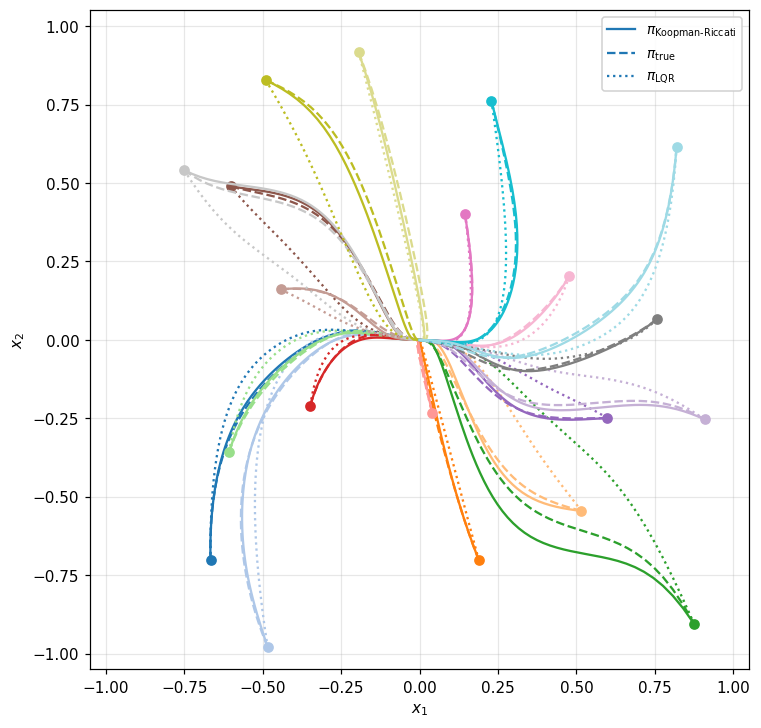

In [6]:
def escape(t, x):
    return 20.0 - np.linalg.norm(x)
escape.terminal = True

def realized_cost(r):
    return trapezoid(np.sum(r.x ** 2, 0) + np.sum(r.u ** 2, 0), r.t)

# stratified sampling: one uniform random point in each of the 5 x 4 cells of [-1, 1]^2
rng = np.random.default_rng(100)
x0_list = [[round(float(-1 + 0.4 * (i + rng.uniform())), 3), round(float(-1 + 0.5 * (j + rng.uniform())), 3)]
           for j in range(4) for i in range(5)]
controllers = {"Koopman-Riccati": lambda t, x: ctrl(x),
               "optimal pi*": lambda t, x: np.array([pi_opt(x)]),
               "linearized LQR": lambda t, x: -K_lqr @ x}
t_eval = np.linspace(0, 10, 501)
runs = {name: [system.simulate(x0, (0, 10), u=c, t_eval=t_eval, solver="RK45", events=escape) for x0 in x0_list]
        for name, c in controllers.items()}

print(f"\n{'x0':>14s} {'v*(x0)':>8s}" + "".join(f"{name:>17s}" for name in controllers))
for i, x0 in enumerate(x0_list):
    print(f"{str(x0):>14s} {v_opt(np.array(x0)):8.4f}" + "".join(f"{realized_cost(runs[name][i]):17.4f}" for name in controllers))

legend_labels = [r"$\pi_{\mathrm{Koopman\text{-}Riccati}}$", r"$\pi_{\mathrm{true}}$", r"$\pi_{\mathrm{LQR}}$"]
fig, ax = plt.subplots(figsize=(7, 7))
for k, x0 in enumerate(x0_list):
    for name, ls, lab in zip(controllers, ["-", "--", ":"], legend_labels):
        r = runs[name][k]
        ax.plot(r.x[0], r.x[1], ls, color=plt.cm.tab20(k), lw=1.5, label=lab if k == 0 else None)
    ax.plot(*x0, "o", color=plt.cm.tab20(k))
ax.set(xlabel="$x_1$", ylabel="$x_2$", xlim=(-1.05, 1.05), ylim=(-1.05, 1.05), aspect="equal")
ax.legend(fontsize=9, loc="best", framealpha=0.9)
plt.tight_layout(); plt.savefig("ex1fig3.png", dpi=300, bbox_inches="tight"); plt.show()

### 1.6 Sensitivity to the kernel, the Yosida parameter $\lambda$, and the number of samples $n$

Each setting is run without and with regularization ($\mu = 0$ and $\mu = 10^{-5}$). For each we check three things:
- whether the closed-loop matrix under the initial LQR policy is Hurwitz, which is required to start Kleinman;
- whether the iteration converges;
- the errors at the samples, and the average realized cost relative to $v^\star$ over the 20 initial states above.

The status column gives the reason why Kleinman stopped.

In [7]:
kernels = {"lin-Matern s=3.5": linear_matern_kernel(2, 3.5, 1.0),
           "lin-Matern s=4.5": linear_matern_kernel(2, 4.5, 1.0),
           "lin-Gaussian 0.5": linear_gaussian_kernel(0.5)}
print(f"{'n':>4s} {'lambda':>6s} {'kernel':>17s} {'mu':>6s} {'cond G':>8s} {'A_u0 Hurwitz':>12s} {'iter':>5s} "
      f"{'err u':>7s} {'err v':>7s} {'cost / v*':>9s}   status")
for n_ in (60, 100):
    for lam_ in (50.0, 100.0, 200.0):
        d = system.collect_data(n_, 1.0, tau=25.0 / lam_, n_time=401, rng=0, solver="RK45", rtol=1e-9, atol=1e-11)
        for kname, k in kernels.items():
            G_, (A0_, A1_) = yosida_matrices(d, k, lam_)
            u0_ = -K_lqr @ d.X0
            for mu_ in (0.0, 1e-5):
                Gmu_ = G_ + mu_ * np.eye(n_)
                hurwitz = np.max(np.linalg.eigvals(np.linalg.solve(Gmu_, A0_ + A1_ * u0_)).real) < 0
                row = f"{n_:4d} {lam_:6.0f} {kname:>17s} {mu_:6.0e} {np.linalg.cond(Gmu_):8.0e} {str(hurwitz):>12s}"
                if not hurwitz:
                    print(row); continue
                P_, u_, info_ = koopman_riccati(G_, [A0_, A1_], d.X0.T @ d.X0, u0_, tol=1e-6, max_iter=500, mu=mu_)
                status = info_["stop"]
                eu = np.linalg.norm(u_[0] - pi_opt(d.X0)) / np.linalg.norm(pi_opt(d.X0))
                ev = np.linalg.norm(np.einsum("in,ij,jn->n", G_, P_, G_) - v_opt(d.X0)) / np.linalg.norm(v_opt(d.X0))
                ratio = np.nan
                if eu < 1.0:                                     # simulate only a sensible policy
                    c_ = KoopmanController(k, d.X0, P_, u_, linear_gaussian_kernel(0.5), reg=1e-3)
                    ratio = np.mean([realized_cost(system.simulate(x0, (0, 10), u=lambda t, x: c_(x), t_eval=t_eval,
                                                                   solver="RK45", events=escape, report=False))
                                     / v_opt(np.array(x0)) for x0 in x0_list])
                print(row + f" {info_['iterations']:5d} {eu:7.3f} {ev:7.0e} {ratio:9.4f}   {status}")

   n lambda            kernel     mu   cond G A_u0 Hurwitz  iter   err u   err v cost / v*   status
[Example 1] data collection: 60 samples x 2 vector fields: total computational time = 0.0582 s


  60     50  lin-Matern s=3.5  0e+00    4e+08        False


  60     50  lin-Matern s=3.5  1e-05    2e+06         True   438   0.094   3e-01    1.0036   converged


  60     50  lin-Matern s=4.5  0e+00    7e+10         True     2   0.179   1e+00    1.0214   A_u not Hurwitz


  60     50  lin-Matern s=4.5  1e-05    2e+06         True    12   0.121   3e-01    1.0111   A_u not Hurwitz


...

 100    200  lin-Matern s=3.5  0e+00    4e+09         True     1   0.517   3e-01    1.1578   A_u not Hurwitz


 100    200  lin-Matern s=3.5  1e-05    3e+06         True    83   0.052   4e-02    1.0024   converged


 100    200  lin-Matern s=4.5  0e+00    8e+11         True     1   0.517   3e-01    1.1578   A_u not Hurwitz


 100    200  lin-Matern s=4.5  1e-05    4e+06         True   121   0.094   6e-02    1.0047   converged


 100    200  lin-Gaussian 0.5  0e+00    7e+11         True     2   0.226   6e-01    1.0204   A_u not Hurwitz
 100    200  lin-Gaussian 0.5  1e-05    1e+06         True     2   0.206   8e-02    1.0205   A_u not Hurwitz


**Observations** ($\gamma(x) = 2 + \cos 2\pi x_1$ on $\mathbb X = [-1, 1]^2$).

- **Main setting** ($n = 100$, $\lambda = 200$, linear–Matérn $s = 4.5$, $\mu = 10^{-5}$; policy interpolation regularized by $10^{-3}$):
  - Kleinman converges to $\|\mathsf u_{\rm new} - \mathsf u\|_\infty < 10^{-6}$ in 121 iterations (about 4 s). After a fast initial phase the convergence is linear, because $\mathsf A_u$ stays close to the stability boundary.
  - At the samples, the relative errors are 9% for $u$ and 6% for $v$. On the grid, $\max|v_{\rm Koopman\text{-}Riccati} - v_{\rm true}| = 0.35$ and $\max|\pi_{\rm Koopman\text{-}Riccati} - \pi_{\rm true}| = 0.84$.
  - In closed loop, from 20 stratified random initial states in $\mathbb X$, the cost is within 1.5% of $v^\star$ (0.5% on average). The linearized LQR is up to 51% worse (16% on average).
- **Regularization of $\mathsf G$ is necessary.** Without $\mu$, $\operatorname{cond}(\mathsf G) \approx 10^{8}$–$10^{12}$ and Kleinman either cannot start or stops after 1–5 iterations, mostly returning the LQR. With $\mu = 10^{-5}$, $\operatorname{cond}(\mathsf G + \mu\mathsf I) \approx 10^{6}$, and every linear–Matérn setting with $n = 100$ and $\lambda \ge 100$ gives a controller within 0.6% of $v^\star$ on average.
- **$\lambda$ and $n$ must be large enough.** At $n = 100$, $\lambda = 50$ mostly cannot start, and $n = 60$ gives larger errors and costs up to 2% above $v^\star$. The linear–Gaussian kernel ($\sigma = 0.5$) stops after 1–2 iterations in all settings.
- **Policy interpolation must be regularized.** With a regularization of $10^{-8}$, the interpolated policy reproduces the samples exactly but overshoots in regions without samples. For some data sets this destabilizes the closed loop from initial states in such regions. A regularization of $10^{-3}$ removed this in all three data sets we tested.

---
## Section 2. Koopmanâ€“Lyapunov controller synthesis

### 2.1 Formulation

With $\mathsf A = \mathsf G^{-1}\mathsf A^0$, $\mathsf B = \mathsf G^{-1}\mathsf A^1$ (with $\mathsf G + \mu\mathsf I$ in place of $\mathsf G$), $\mathsf X = (\mathsf{GPG})^{-1}$, $\mathsf U = \mathsf F\mathsf X$, and $\mathsf Q = \mathsf L\mathsf L^\top$ ($\mathsf L = [x_1, \dots, x_n]^\top$), we solve the SDP
$$
\min_{\mathsf X, \mathsf U}\ -\log\det\mathsf X \quad \text{s.t.} \quad
\begin{bmatrix} -(\mathsf{AX} + \mathsf{XA}^\top + \mathsf{BU} + \mathsf U^\top\mathsf B^\top) & \mathsf{XL} \\ \mathsf L^\top\mathsf X & \mathsf I\end{bmatrix} \succeq 0, \quad
\epsilon_X\mathsf I \preceq \mathsf X \preceq \alpha_X\mathsf I, \quad
\mathsf L_0^\top\mathsf X\mathsf L_0 \preceq \alpha_0\mathsf I.
$$
- **Reference bound:** $\mathsf L_0 = \mathsf X_0^\top \mathsf P_{\rm LQR}^{1/2}$, where $\mathsf P_{\rm LQR}$ is the Riccati matrix of the linearized LQR. The constraint $\mathsf L_0^\top\mathsf X\mathsf L_0 \preceq \alpha_0\mathsf I$ is equivalent to $\mathsf{GPG} \succeq \alpha_0^{-1}\,\mathsf L_0\mathsf L_0^\top$, i.e. $v \succeq v_{\rm LQR}/\alpha_0$ at the samples. It prevents the box from making $v$ flat at the samples, in which case its Lie derivatives cannot be resolved by the data.
- **Policy recovery:** $\mathsf u = -\operatorname{diag}(\mathsf{YB})$ with $\mathsf Y = \mathsf{GPG}$, i.e. $u(x_i) = -\tfrac12 L_{f_1}v(x_i)$ on the data. Where it violates the diagonal descent condition (21), $c_i + 2a_iu_i \le 0$ with $a_i = (\mathsf{YB})_{ii}$ and $c_i = 2(\mathsf{YA})_{ii} + \mathsf Q_{ii}$, and the input acts on $v$ ($|a_i| \ge \beta\max_k|a_k|$), $u_i$ is projected onto it.
- **Settings:** $n = 50$ (the SDP has $O(n^2)$ variables), the kernel and Yosida parameters of Section 1 ($s = 4.5$, length scale 1, $\lambda = 200$, $\theta = 0.125$, $\mu = 10^{-5}$), $\epsilon_X = 10^{-4}$, $\alpha_X = 300$, $\alpha_0 = 1$, $\beta = 0.05$; MOSEK.

In [8]:
n_kl = 50
data_kl = system.collect_data(n_kl, 1.0, tau=theta, n_time=401, rng=0, solver="RK45", rtol=1e-9, atol=1e-11)
X0_kl = data_kl.X0
G_kl, (A0_kl, A1_kl) = yosida_matrices(data_kl, kernel, lam)
L_kl = X0_kl.T                                                   # Q = L L', Q_ii' = x_i . x_i'
L0_kl = X0_kl.T @ np.real(sqrtm(system.P))                       # G P0 G = X0' P_LQR X0 = L0 L0'
P_kl, u_kl, info_kl = koopman_lyapunov(G_kl, [A0_kl, A1_kl], L_kl, L0_kl, mu=mu, eps=1e-4,
                                       alpha_box=300.0, alpha_ref=1.0, beta=0.05)
print(f"SDP: {info_kl['status']}, computational time = {info_kl['sdp_time']:.2f} s (total {info_kl['wall_time']:.2f} s)")
print(f"recovery: safeguard applied at {info_kl['n_safeguarded']} samples; condition (21) violated at {info_kl['n_violated']} samples "
      f"(there |a_i| / max|a| = {np.round(np.abs(info_kl['a'][0][info_kl['c'] + 2 * info_kl['a'][0] * u_kl[0] > 1e-12]) / np.abs(info_kl['a']).max(), 4)})")
v_kl_s = np.einsum("in,ij,jn->n", G_kl, P_kl, G_kl)
print(f"at the samples: rel. error of u = {np.linalg.norm(u_kl[0] - pi_opt(X0_kl)) / np.linalg.norm(pi_opt(X0_kl)):.3f}, "
      f"rel. error of v = {np.linalg.norm(v_kl_s - v_opt(X0_kl)) / np.linalg.norm(v_opt(X0_kl)):.3f}")
ctrl_kl = KoopmanController(kernel, X0_kl, P_kl, u_kl, linear_gaussian_kernel(0.5), reg=1e-3)
ctrl_kl.name = "Koopman-Lyapunov"

[Example 1] data collection: 50 samples x 2 vector fields: total computational time = 0.0202 s


SDP: optimal, computational time = 3.82 s (total 3.82 s)
recovery: safeguard applied at 1 samples; condition (21) violated at 1 samples (there |a_i| / max|a| = [0.0009])
at the samples: rel. error of u = 0.034, rel. error of v = 0.002


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2325: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2325: RuntimeWarning: overflow encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/linalg/_linalg.py:2325: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044KoopmanLQR/codes-koopman-lqr/koopman_synthesis.py:128: RuntimeWarning: divide by zero encountered in matmul
  a = np.stack([np.diag(Y @ B) for B in Bs])                              # (m, n)
/Users/wentaotang/Library/CloudStorage/Dropbox/1 - Manuscripts/044Koo

### 2.2 Value function and policy

on the grid over [-1,1]^2: max |v_KL - v_true| = 0.055, max |pi_KL - pi_true| = 1.006


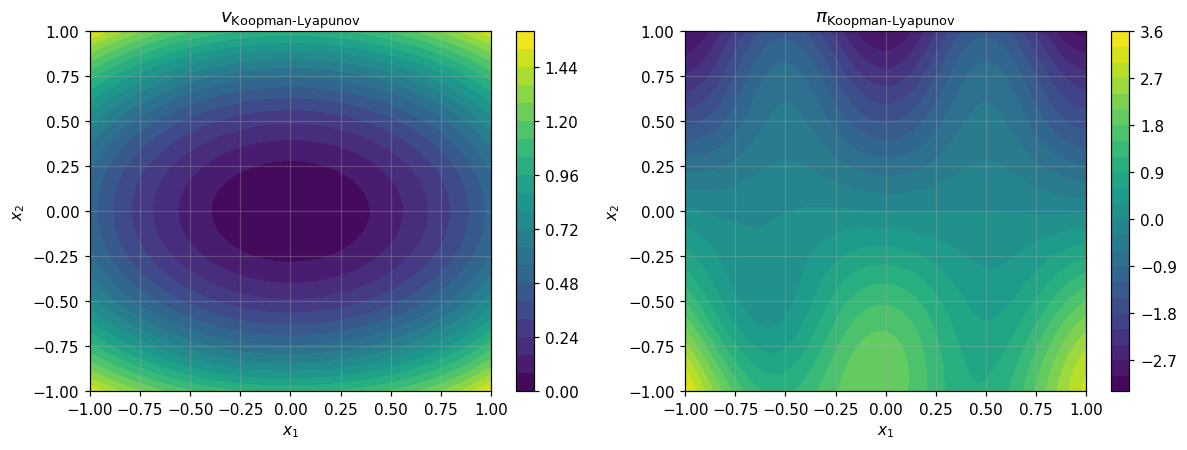

In [9]:
V_kl = ctrl_kl.value(Xg).reshape(g1.shape)
Pi_kl = ctrl_kl.policy_model.predict(Xg)[0].reshape(g1.shape)
print(f"on the grid over [-1,1]^2: max |v_KL - v_true| = {np.abs(V_kl - Vs).max():.3f}, max |pi_KL - pi_true| = {np.abs(Pi_kl - Pis).max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, Z, name in zip(ax, (V_kl, Pi_kl), ("v", "\\pi")):
    cs = a.contourf(g1, g2, Z, levels=21, cmap="viridis")
    a.set(title=f"${name}_{{\\mathrm{{Koopman\\text{{-}}Lyapunov}}}}$", xlabel="$x_1$", ylabel="$x_2$")
    fig.colorbar(cs, ax=a)
plt.tight_layout(); plt.savefig("ex1fig4.png", dpi=300, bbox_inches="tight"); plt.show()

### 2.3 Closed-loop performance

The same 20 initial states as in Section 1.5. The table gives the mean and worst realized cost relative to $v^\star(x_0)$, the number of runs that reach the origin, and the mean computational time of one closed-loop simulation on $[0, 10]$.

controller              mean     worst  reached   time per closed loop
Koopman-Lyapunov      +3.42%   +39.11%    20/20              10.3 ms
Koopman-Riccati       +0.47%    +1.50%    20/20              11.0 ms
optimal pi*           +0.07%    +0.30%    20/20               3.9 ms
linearized LQR       +15.75%   +51.15%    20/20               3.8 ms


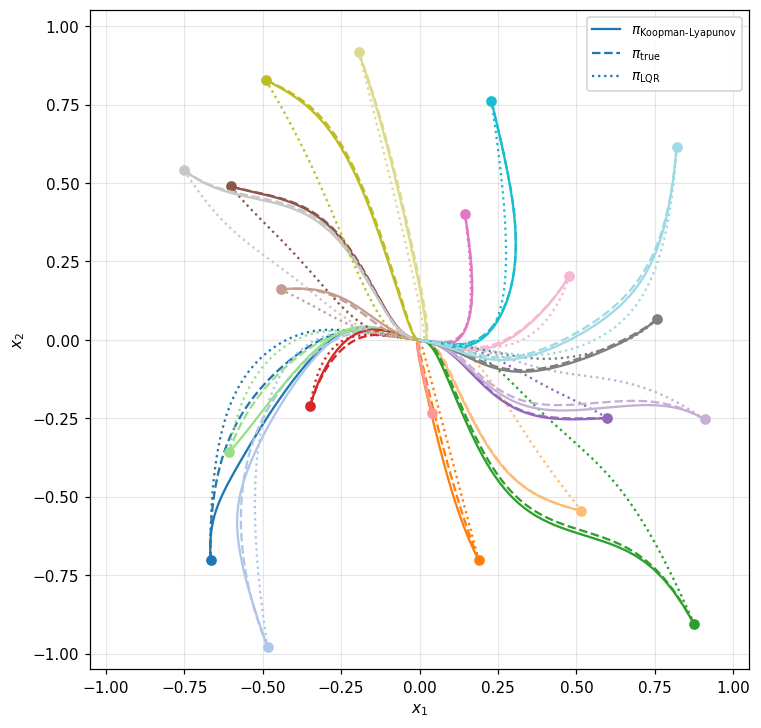

In [10]:
ctrls_kl = {"Koopman-Lyapunov": lambda t, x: ctrl_kl(x),
            "Koopman-Riccati": lambda t, x: ctrl(x),
            "optimal pi*": lambda t, x: np.array([pi_opt(x)]),
            "linearized LQR": lambda t, x: -K_lqr @ x}
runs_kl, times_kl = {}, {}
for name, c_ in ctrls_kl.items():
    runs_kl[name], times_kl[name] = [], []
    for x0 in x0_list:
        t0 = time.perf_counter()
        runs_kl[name].append(system.simulate(x0, (0, 10), u=c_, t_eval=t_eval, solver="RK45", events=escape, report=False))
        times_kl[name].append(time.perf_counter() - t0)
vstar = np.array([v_opt(np.array(x0)) for x0 in x0_list])
print(f"{'controller':18s} {'mean':>9s} {'worst':>9s} {'reached':>8s} {'time per closed loop':>22s}")
for name in ctrls_kl:
    r = np.array([realized_cost(q) for q in runs_kl[name]]) / vstar
    ok = sum(np.linalg.norm(q.x[:, -1]) < 1e-2 for q in runs_kl[name])
    print(f"{name:18s} {100 * (r.mean() - 1):+8.2f}% {100 * (r.max() - 1):+8.2f}% {ok:5d}/20 {1e3 * np.mean(times_kl[name]):17.1f} ms")

legend_kl = {"Koopman-Lyapunov": r"$\pi_{\mathrm{Koopman\text{-}Lyapunov}}$", "optimal pi*": r"$\pi_{\mathrm{true}}$",
             "linearized LQR": r"$\pi_{\mathrm{LQR}}$"}
fig, ax = plt.subplots(figsize=(7, 7))
for k, x0 in enumerate(x0_list):
    for name, ls in zip(legend_kl, ["-", "--", ":"]):
        r = runs_kl[name][k]
        ax.plot(r.x[0], r.x[1], ls, color=plt.cm.tab20(k), lw=1.5, label=legend_kl[name] if k == 0 else None)
    ax.plot(*x0, "o", color=plt.cm.tab20(k))
ax.set(xlabel="$x_1$", ylabel="$x_2$", xlim=(-1.05, 1.05), ylim=(-1.05, 1.05), aspect="equal")
ax.legend(fontsize=9, loc="best", framealpha=0.9)
plt.tight_layout(); plt.savefig("ex1fig5.png", dpi=300, bbox_inches="tight"); plt.show()

**Observations.**

- **SDP:** solved in about 11 s ($n = 50$). With the reference bound ($\alpha_0 = 1$), the Lyapunov function is essentially the LQR value: the relative error of $v$ at the samples is 0.2%, and $\max|v_{\rm Koopman\text{-}Lyapunov} - v_{\rm true}| = 0.055$ on the grid. In this example the LQR value $x^\top\mathsf P_{\rm LQR}x = \tfrac12x_1^2 + x_2^2$ coincides with $v^\star$, so the reference bound is particularly favourable here.
- **Policy:** the recovery $\mathsf u = -\operatorname{diag}(\mathsf{YB})$ gives a 3.4% relative error at the samples. The safeguard is applied at one sample; condition (21) remains violated at one sample, where $|a_i|$ is 0.09% of its maximum, i.e. where the input has essentially no effect on $v$ (Assumption 3.16 nearly fails).
- **Closed loop:** the Koopman–Lyapunov controller stabilizes the system from all 20 states. Its cost is 3.4% above $v^\star$ on average and 39% at worst, compared with 0.5% and 1.5% for the Koopman–Riccati controller ($n = 100$) and 16% and 51% for the linearized LQR. The Koopman–Lyapunov synthesis is a stabilization method: it certifies descent of $v$, but does not optimize the cost; its policy is accurate where the input acts strongly on $v$, and less so elsewhere (max $|\pi_{\rm Koopman\text{-}Lyapunov} - \pi_{\rm true}| = 1.0$ on the grid).